## Chargement et exploration des données

In [1]:
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import LabelEncoder

#  Charger dataset Dry Bean (ID 602)
dry_bean = fetch_ucirepo(id=602)

X = dry_bean.data.features   # DataFrame : 16 variables morphologiques
y = dry_bean.data.targets    # DataFrame : 1 colonne, la classe (texte)

# Exploration
print("Forme de X :", X.shape)
print("Forme de y :", y.shape)
print("\nTypes de X :\n", X.dtypes)
print("\nAperçu de y :\n", y.head())
print("\nClasses distinctes :", y.iloc[:, 0].unique())
print("\nEffectifs par classe :\n", y.iloc[:, 0].value_counts())
print("\nValeurs manquantes dans X :", X.isna().sum().sum())

# Encodage des étiquettes textuelles en entiers
le = LabelEncoder()
y_enc = le.fit_transform(y.values.ravel())   # tableau NumPy 1D d'entiers

print("\nCorrespondance classes -> entiers :")
for i, nom in enumerate(le.classes_):
    print(i, "->", nom)
print("Valeurs encodées :", np.unique(y_enc))

Forme de X : (13611, 16)
Forme de y : (13611, 1)

Types de X :
 Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRatio        float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
Roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
dtype: object

Aperçu de y :
    Class
0  SEKER
1  SEKER
2  SEKER
3  SEKER
4  SEKER

Classes distinctes : ['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']

Effectifs par classe :
 Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Valeurs manquantes dans X : 0

Correspondance classes -> entiers :
0 -> BARBUNYA
1 -> BOMBAY
2 -> CALI
3 -> DERMASON
4 -> HOROZ
5 -> SEKER
6 -> SIRA
Valeurs e

**Analyse:** Le dataset Dry Bean contient 13 611 échantillons décrits par 16 variables morphologiques toutes numériques (aire, périmètre, longueurs d'axes, compacité, etc.), sans valeur manquante. les classes sont ici des **chaînes de caractères** (7 variétés) j'ai donc utilisé `LabelEncoder` pour convertir chaque variété en un entier de 0 à 6. 

## Préparation et séparation des données

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Premier découpage : 60 % train / 40 % reste
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_enc,
    test_size=0.40,
    stratify=y_enc,
    random_state=42
)

# le reste est coupé en deux moitiés (20 % val / 20 % test)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Train :", X_train.shape, y_train.shape)
print("Val   :", X_val.shape, y_val.shape)
print("Test  :", X_test.shape, y_test.shape)

# 3. Normalisation niquement sur le train
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   
X_val   = scaler.transform(X_val)         
X_test  = scaler.transform(X_test)        


Train : (8166, 16) (8166,)
Val   : (2722, 16) (2722,)
Test  : (2723, 16) (2723,)

Moyenne train (≈ 0) : [ 0. -0. -0. -0.  0.  0.  0.  0. -0.  0.  0.  0. -0. -0. -0. -0.]
Écart-type train (≈ 1) : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Proportions des classes (train) : [0.09710997 0.03832966 0.11976488 0.26047024 0.14168504 0.14891012
 0.1937301 ]
Proportions des classes (val)   : [0.09735489 0.03857458 0.11976488 0.26047024 0.14144012 0.14878766
 0.19360764]
Proportions des classes (test)  : [0.09695189 0.03819317 0.1197209  0.26074183 0.14175542 0.14910026
 0.19353654]


## Définition de l’architecture MLP avec Sequential et Dense

In [15]:
from tensorflow import keras
from tensorflow.keras import layers

n_features = X_train.shape[1]          # 16
n_classes = len(np.unique(y_enc))      # 7

model = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(64, activation="relu"),
    #layers.Dense(32, activation="relu"),
    layers.Dense(n_classes, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,543 (6.03 KB)

 Trainable params: 1,543 (6.03 KB)

 Non-trainable params: 0 (0.00 B)

**Choix de l'architecture:** Les données étant tabulaires et déjà à plat (16 variables), il n'y a pas besoin de `Flatten`. Le modèle final comporte **une couche cachée** de 64 neurones avec activation ReLU, qui introduit la non-linéarité, et une couche de sortie de 7 neurones avec `softmax`, qui produit une probabilité par variété. J'avais d'abord testé deux couches cachées, mais ce modèle sur-apprenait. Réduire la capacité à une seule couche a corrigé le problème.

## Configuration de l’apprentissage

In [16]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

**Choix:** L'optimiseur `Adam` (taux d'apprentissage 0,001) adapte le pas de chaque poids et converge rapidement avec peu de réglages. La perte `sparse_categorical_crossentropy` est adaptée à la classification multiclasse avec des étiquettes entières. L'accuracy sert uniquement de métrique de suivi.

## Entraînement avec fit

In [17]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=50,
    verbose=1
)

# Inspection de l'objet history
print(history.history.keys())
print("Précision finale train :", history.history["accuracy"][-1])
print("Précision finale val   :", history.history["val_accuracy"][-1])
print("Perte finale train     :", history.history["loss"][-1])
print("Perte finale val       :", history.history["val_loss"][-1])

Epoch 1/50
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7529 - loss: 0.8019 - val_accuracy: 0.8865 - val_loss: 0.4094
Epoch 2/50
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9068 - loss: 0.3201 - val_accuracy: 0.9140 - val_loss: 0.2692
Epoch 3/50
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9177 - loss: 0.2454 - val_accuracy: 0.9236 - val_loss: 0.2307
Epoch 4/50
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9230 - loss: 0.2225 - val_accuracy: 0.9243 - val_loss: 0.2151
Epoch 5/50
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9246 - loss: 0.2126 - val_accuracy: 0.9273 - val_loss: 0.2096
Epoch 6/50
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9243 - loss: 0.2059 - val_accuracy: 0.9258 - val_loss: 0.2051
Epoch 7/50
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9280 - loss: 0.2018 - val_accuracy: 0.9269 - val_loss: 0.2005
Epoch 8/50
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9274 - loss: 0.1981 - val_accuracy: 0.

**Analyse:** L'entraînement utilise des lots de 32 échantillons, soit 256 mises à jour par époque, sur 50 époques, avec le jeu de validation pour surveiller la généralisation sans modifier les poids. La perte d'entraînement diminue rapidement au début puis plus lentement, et la précision de validation se stabilise autour de 93 %.

## Visualisation et analyse des courbes d’apprentissage

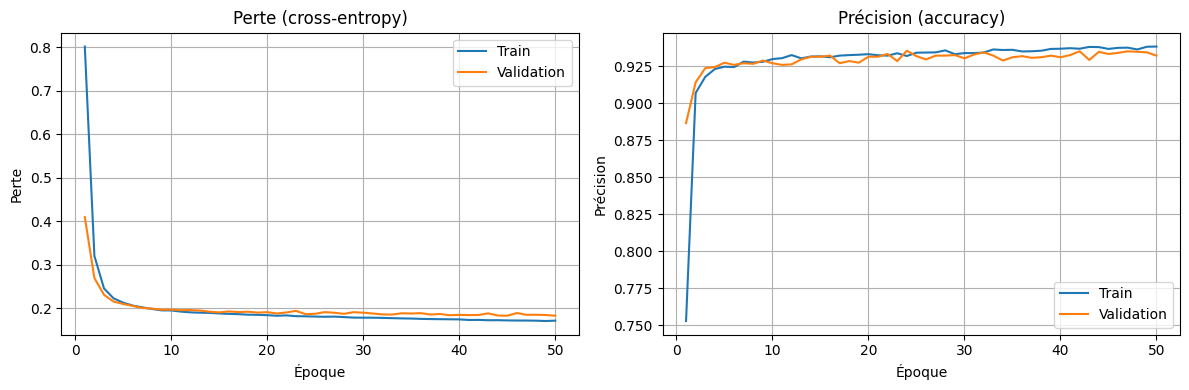

Meilleure époque (val_loss minimale) : 45
Écart final de précision (train - val) : 0.0061


In [18]:
import matplotlib.pyplot as plt

hist = history.history
epochs_range = range(1, len(hist["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Courbes de perte
axes[0].plot(epochs_range, hist["loss"], label="Train")
axes[0].plot(epochs_range, hist["val_loss"], label="Validation")
axes[0].set_title("Perte (cross-entropy)")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Perte")
axes[0].legend()
axes[0].grid(True)

# Courbes de précision
axes[1].plot(epochs_range, hist["accuracy"], label="Train")
axes[1].plot(epochs_range, hist["val_accuracy"], label="Validation")
axes[1].set_title("Précision (accuracy)")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Précision")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Repérer l'époque où la perte de validation est minimale
best_epoch = int(np.argmin(hist["val_loss"])) + 1
print("Meilleure époque (val_loss minimale) :", best_epoch)
print("Écart final de précision (train - val) :",
      round(hist["accuracy"][-1] - hist["val_accuracy"][-1], 4))

**Analyse des courbes:** Avec deux couches cachées, les courbes divergeaient : la meilleure époque était la 1re et l'écart de précision train-validation atteignait 2,7 points, signe de **sur-apprentissage**. Après suppression d'une couche, la meilleure époque passe à 45 et l'écart tombe à 0,6 point : les courbes sont presque superposées, ce qui indique un **bon ajustement**.

## Évaluation et analyse des performances

86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Matrice de confusion :
 [[247   0  12   0   1   1   4]
 [  0 105   0   0   0   0   0]
 [ 12   0 305   0   5   2   2]
 [  0   0   0 648   0  13  48]
 [  2   0   6   5 367   0   5]
 [  1   0   0   7   1 389   7]
 [  2   0   0  39   4   6 476]]


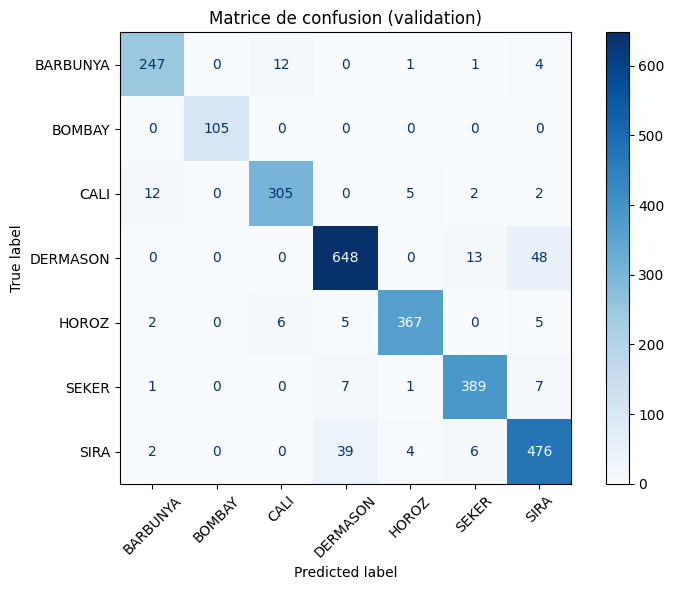

              precision    recall  f1-score   support

    BARBUNYA      0.936     0.932     0.934       265
      BOMBAY      1.000     1.000     1.000       105
        CALI      0.944     0.936     0.940       326
    DERMASON      0.927     0.914     0.920       709
       HOROZ      0.971     0.953     0.962       385
       SEKER      0.946     0.960     0.953       405
        SIRA      0.878     0.903     0.891       527

    accuracy                          0.932      2722
   macro avg      0.943     0.943     0.943      2722
weighted avg      0.932     0.932     0.932      2722



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# rédictions sur le jeu de validation
y_proba = model.predict(X_val)              # shape (2722, 7) : probabilités par classe
y_pred = np.argmax(y_proba, axis=1)         # classe la plus probable

# Matrice de confusion
cm = confusion_matrix(y_val, y_pred)
print("Matrice de confusion :\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Matrice de confusion (validation)")
plt.tight_layout()
plt.show()

# Rapport de classification
print(classification_report(y_val, y_pred, target_names=le.classes_, digits=3))

**Interprétation:** L'accuracy sur la validation est d'environ 93 %. La classe BOMBAY est quasi parfaitement reconnue car elle est très distincte des autres. Les erreurs se concentrent entre **SIRA, SEKER et DERMASON**, des variétés aux morphologies proches.

## Optimisation, régularisation et arrêt précoce

base (lr=1e-3)     | arrêt à l'époque  40 | meilleure époque  30 | val_loss 0.1818 | val_acc 0.9324
lr=1e-2            | arrêt à l'époque  33 | meilleure époque  23 | val_loss 0.1881 | val_acc 0.9295
lr=1e-4            | arrêt à l'époque 200 | meilleure époque 200 | val_loss 0.1903 | val_acc 0.9291
L2=1e-3            | arrêt à l'époque  62 | meilleure époque  52 | val_loss 0.1975 | val_acc 0.9346
Dropout=0.3        | arrêt à l'époque  71 | meilleure époque  61 | val_loss 0.1854 | val_acc 0.9342


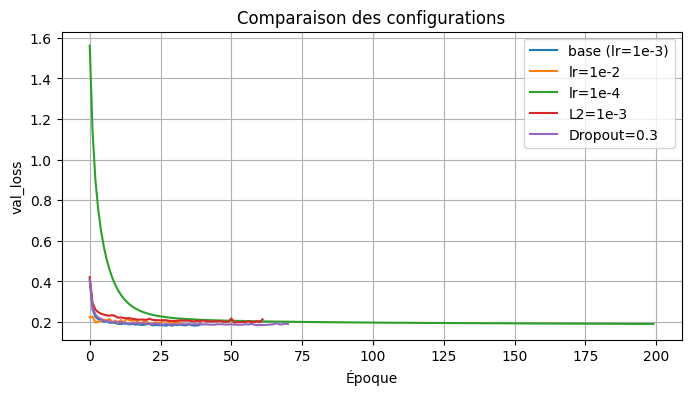

In [20]:
from tensorflow.keras import regularizers, callbacks

def build_model(units=64, lr=0.001, l2=0.0, dropout=0.0):
    m = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(units, activation="relu",
                     kernel_regularizer=regularizers.l2(l2) if l2 > 0 else None),
        layers.Dropout(dropout) if dropout > 0 else layers.Identity(),
        layers.Dense(n_classes, activation="softmax")
    ])
    m.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return m

# Callback d'arrêt précoce
early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Expériences : (nom, paramètres)
configs = {
    "base (lr=1e-3)":        dict(lr=0.001),
    "lr=1e-2":               dict(lr=0.01),
    "lr=1e-4":               dict(lr=0.0001),
    "L2=1e-3":               dict(lr=0.001, l2=1e-3),
    "Dropout=0.3":           dict(lr=0.001, dropout=0.3),
}

results = {}
histories = {}
for name, params in configs.items():
    m = build_model(**params)
    h = m.fit(X_train, y_train,
              validation_data=(X_val, y_val),
              batch_size=32, epochs=200,
              callbacks=[early_stop], verbose=0)
    histories[name] = h.history
    best = int(np.argmin(h.history["val_loss"]))
    results[name] = (best + 1,
                     h.history["val_loss"][best],
                     h.history["val_accuracy"][best])
    print(f"{name:18s} | arrêt à l'époque {len(h.history['loss']):3d} | "
          f"meilleure époque {best+1:3d} | val_loss {h.history['val_loss'][best]:.4f} "
          f"| val_acc {h.history['val_accuracy'][best]:.4f}")

# Courbes de val_loss comparées
plt.figure(figsize=(8, 4))
for name, h in histories.items():
    plt.plot(h["val_loss"], label=name)
plt.xlabel("Époque"); plt.ylabel("val_loss")
plt.title("Comparaison des configurations"); plt.legend(); plt.grid(True)
plt.show()

##   Évaluation finale sur le jeu de test

Test loss : 0.2064
Test accuracy : 0.9240
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

F1 macro : 0.9362

               precision    recall  f1-score   support

    BARBUNYA      0.938     0.917     0.927       264
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.954     0.945     0.949       326
    DERMASON      0.923     0.914     0.919       710
       HOROZ      0.949     0.969     0.959       386
       SEKER      0.923     0.948     0.936       406
        SIRA      0.866     0.861     0.864       527

    accuracy                          0.924      2723
   macro avg      0.936     0.936     0.936      2723
weighted avg      0.924     0.924     0.924      2723



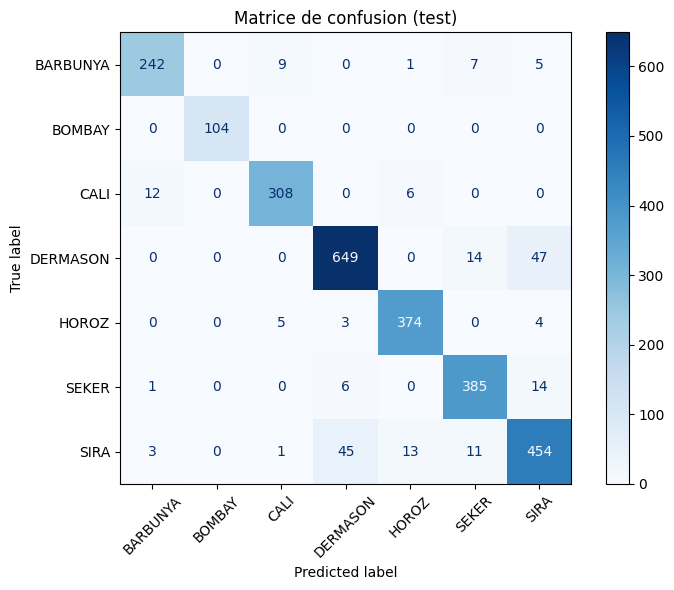

In [21]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, f1_score

# 
keras.utils.set_random_seed(42)
final_model = build_model(units=64, lr=0.001)

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

final_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=200,
    callbacks=[early_stop],
    verbose=0
)

# Évaluation sur le jeu de test 
test_loss, test_acc = final_model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss : {test_loss:.4f}")
print(f"Test accuracy : {test_acc:.4f}")

# Prédictions détaillées
y_proba_test = final_model.predict(X_test)
y_pred_test = np.argmax(y_proba_test, axis=1)

print("\nF1 macro :", round(f1_score(y_test, y_pred_test, average="macro"), 4))
print("\n", classification_report(y_test, y_pred_test, target_names=le.classes_, digits=3))

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred_test)
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Matrice de confusion (test)")
plt.tight_layout()
plt.show()

**Résultat final.** Sur le jeu de test, jamais utilisé pendant l'entraînement ni le choix des hyperparamètres, le modèle obtient une accuracy de **92,4 %** et un F1 macro de **0,936**, proches des résultats de validation (≈ 93 %). Le modèle généralise donc bien. BOMBAY est parfaitement reconnue (F1 = 1,000), tandis que SIRA est la classe la plus difficile (F1 = 0,864) car sa morphologie ressemble à celle de DERMASON et de SEKER.